# PRML Lab 3 — Bagging & Boosting
**Aryan Tiwari (B20AI056)** · CSL2050 Pattern Recognition & Machine Learning · Winter 2022

Tasks 1–8 of Q1 and 1–3 of Q2 use a CART decision tree written from scratch (below); sklearn / XGBoost / LightGBM are used only where the assignment asks for them.

In [1]:
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, KFold, StratifiedKFold
from sklearn.ensemble import RandomForestRegressor, AdaBoostRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error
import xgboost as xgb
import lightgbm as lgb

warnings.filterwarnings('ignore', category=UserWarning)
SEED = 56
rng = np.random.default_rng(SEED)
sns.set_theme(style='whitegrid')
results = {}

def savefig(name):
    plt.savefig(f'figures/{name}.png', dpi=150, bbox_inches='tight')

## A CART tree from scratch
One class handles both tasks. At each node, every feature is sorted once and all thresholds are scored in a single pass using cumulative sums:
- **regression** — minimise the summed squared error of the two children (variance reduction); leaves predict the mean;
- **classification** — minimise the weighted Gini impurity; leaves predict the majority class.

Growth stops at `max_depth`, when a node has fewer than `min_samples_split` samples, or when it is pure.

In [2]:
class CART:
    def __init__(self, task='regression', max_depth=None, min_samples_split=2):
        self.task = task
        self.max_depth = max_depth if max_depth is not None else np.inf
        self.min_samples_split = min_samples_split

    def _leaf(self, y):
        if self.task == 'regression':
            return float(y.mean())
        return int(np.bincount(y, minlength=self.n_classes).argmax())

    def _best_split(self, X, y):
        n = len(y)
        best = (np.inf, None, None)
        for j in range(X.shape[1]):
            order = np.argsort(X[:, j], kind='mergesort')
            xs, ys = X[order, j], y[order]
            valid = np.nonzero(xs[1:] != xs[:-1])[0]          # split after position i (left = 0..i)
            if not len(valid):
                continue
            nl = np.arange(1, n)
            if self.task == 'regression':
                cs, cs2 = np.cumsum(ys)[:-1], np.cumsum(ys ** 2)[:-1]
                tot, tot2 = ys.sum(), (ys ** 2).sum()
                sse_l = cs2 - cs ** 2 / nl
                sse_r = (tot2 - cs2) - (tot - cs) ** 2 / (n - nl)
                cost = sse_l + sse_r
            else:
                onehot = np.eye(self.n_classes)[ys]
                cl = np.cumsum(onehot, axis=0)[:-1]
                cr = onehot.sum(0) - cl
                gini_l = 1 - ((cl / nl[:, None]) ** 2).sum(1)
                gini_r = 1 - ((cr / (n - nl)[:, None]) ** 2).sum(1)
                cost = (nl * gini_l + (n - nl) * gini_r) / n
            i = valid[np.argmin(cost[valid])]
            if cost[i] < best[0]:
                best = (cost[i], j, (xs[i] + xs[i + 1]) / 2)
        return best[1], best[2]

    def _grow(self, X, y, depth):
        pure = np.all(y == y[0])
        if depth >= self.max_depth or len(y) < self.min_samples_split or pure:
            return self._leaf(y)
        j, t = self._best_split(X, y)
        if j is None:
            return self._leaf(y)
        m = X[:, j] <= t
        return (j, t, self._grow(X[m], y[m], depth + 1), self._grow(X[~m], y[~m], depth + 1))

    def fit(self, X, y):
        X = np.asarray(X, float)
        y = np.asarray(y)
        if self.task == 'classification':
            self.n_classes = int(y.max()) + 1
        self.root = self._grow(X, y, 0)
        return self

    def _predict_one(self, x):
        node = self.root
        while isinstance(node, tuple):
            j, t, left, right = node
            node = left if x[j] <= t else right
        return node

    def predict(self, X):
        return np.array([self._predict_one(x) for x in np.asarray(X, float)])


def r2(y, p):
    return 1 - np.sum((y - p) ** 2) / np.sum((y - np.mean(y)) ** 2)

def accuracy(y, p):
    return float(np.mean(y == p))

# Question 1 — Housing prices (regression)

In [3]:
house = pd.read_csv('data/Housing.csv')
print(house.shape, '| missing:', house.isna().sum().sum(), '| duplicates:', house.duplicated().sum())
house.head()

(545, 13) | missing: 0 | duplicates: 0


,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


**Pre-processing.**
- Six yes/no columns → 0/1.
- `furnishingstatus` is ordinal: unfurnished (0) < semi-furnished (1) < furnished (2).
- Price is expressed in **lakhs** (÷10⁵) so errors are readable. Trees are invariant to monotonic feature scaling, so features are not normalised.
- 80:20 train/test split; `Xtrain` is the 80% used for every model and for cross-validation, and the test set is touched only for final scores.

Xtrain (436, 12) | Xtest (109, 12)


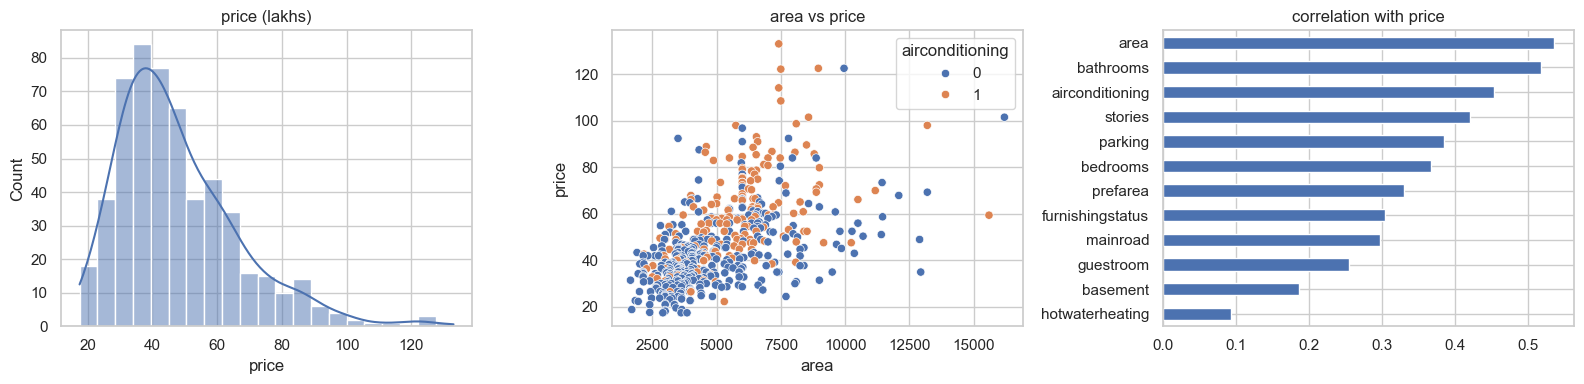

In [4]:
YES_NO = ['mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'prefarea']
h = house.copy()
h[YES_NO] = (h[YES_NO] == 'yes').astype(int)
h['furnishingstatus'] = h['furnishingstatus'].map({'unfurnished': 0, 'semi-furnished': 1, 'furnished': 2})
h['price'] = h['price'] / 1e5
H_FEATS = h.columns.drop('price').tolist()
Xh, yh = h[H_FEATS].values.astype(float), h['price'].values
Xtrain, Xtest, ytrain, ytest = train_test_split(Xh, yh, test_size=0.2, random_state=SEED)
print('Xtrain', Xtrain.shape, '| Xtest', Xtest.shape)

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(h['price'], kde=True, ax=ax[0]); ax[0].set_title('price (lakhs)')
sns.scatterplot(data=h, x='area', y='price', hue='airconditioning', ax=ax[1]); ax[1].set_title('area vs price')
h.corr()['price'].drop('price').sort_values().plot.barh(ax=ax[2]); ax[2].set_title('correlation with price')
plt.tight_layout(); savefig('q1_eda'); plt.show()

### 1. A single fully-grown regression tree (no validation)

In [5]:
full_tree = CART('regression').fit(Xtrain, ytrain)
r2_train_full, r2_test_full = r2(ytrain, full_tree.predict(Xtrain)), r2(ytest, full_tree.predict(Xtest))
results['q1_t1'] = {'train_r2': r2_train_full, 'test_r2': r2_test_full}
print(f'R² train = {r2_train_full:.4f} | R² test = {r2_test_full:.4f}')

R² train = 0.9987 | R² test = 0.4207


With no depth limit the tree grows until every leaf is pure: it fits the training set perfectly but generalises poorly. This is the high-variance behaviour that bagging is meant to fix.

### 2–3. 5-fold cross-validation for `max_depth`

In [6]:
kf = KFold(5, shuffle=True, random_state=SEED)
depths = range(1, 16)
cv = np.zeros((len(depths), 5))
for i, d in enumerate(depths):
    for k, (tr, va) in enumerate(kf.split(Xtrain)):
        m = CART('regression', max_depth=d).fit(Xtrain[tr], ytrain[tr])
        cv[i, k] = r2(ytrain[va], m.predict(Xtrain[va]))
cv_df = pd.DataFrame(cv, index=list(depths), columns=[f'fold {k+1}' for k in range(5)])
cv_df['mean'], cv_df['std'] = cv.mean(1), cv.std(1)
best_depth = int(cv_df['mean'].idxmax())
results['q1_cv'] = {'best_depth': best_depth, 'mean_r2': cv_df['mean'].round(4).to_dict(), 'std_r2': cv_df['std'].round(4).to_dict()}
print('best max_depth =', best_depth, '| mean CV R² =', round(cv_df.loc[best_depth, 'mean'], 4))
cv_df.round(3)

best max_depth = 3 | mean CV R² = 0.4606


,fold 1,fold 2,fold 3,fold 4,fold 5,mean,std
1,0.068,0.215,0.368,0.303,0.376,0.266,0.114
2,0.090,0.282,0.465,0.401,0.495,0.347,0.148
3,0.259,0.388,0.580,0.528,0.548,0.461,0.120
4,0.338,0.412,0.589,0.387,0.355,0.416,0.090
5,0.372,0.172,0.644,0.366,0.256,0.362,0.159
6,0.350,0.168,0.716,0.354,0.219,0.361,0.192
7,0.270,0.106,0.643,0.368,0.212,0.320,0.183
8,0.201,0.060,0.586,0.387,0.139,0.275,0.189
9,0.194,0.020,0.530,0.411,0.141,0.259,0.185
10,0.193,0.016,0.522,0.405,0.126,0.252,0.185


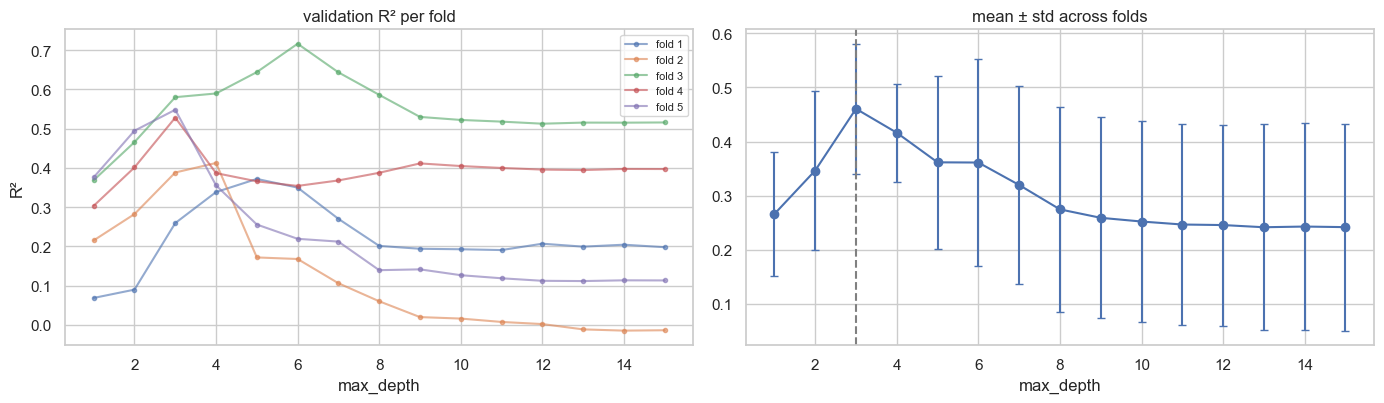

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
for k in range(5):
    ax[0].plot(list(depths), cv[:, k], 'o-', ms=3, alpha=0.6, label=f'fold {k+1}')
ax[0].set_title('validation R² per fold'); ax[0].set_xlabel('max_depth'); ax[0].set_ylabel('R²'); ax[0].legend(fontsize=8)
ax[1].errorbar(list(depths), cv_df['mean'], yerr=cv_df['std'], fmt='o-', capsize=3)
ax[1].axvline(best_depth, ls='--', c='grey'); ax[1].set_title('mean ± std across folds'); ax[1].set_xlabel('max_depth')
plt.tight_layout(); savefig('q1_cv_depth'); plt.show()

### 4–5. Bagging — 10 bootstrap datasets, one tree each (depth chosen by CV)

In [8]:
def bootstrap_trees(X, y, n_estimators, max_depth, seed=SEED):
    r = np.random.default_rng(seed)
    trees = []
    for _ in range(n_estimators):
        idx = r.integers(0, len(y), len(y))            # sample n rows with replacement
        trees.append(CART('regression', max_depth=max_depth).fit(X[idx], y[idx]))
    return trees

trees = bootstrap_trees(Xtrain, ytrain, 10, best_depth)
unique_frac = [len(np.unique(np.random.default_rng(SEED).integers(0, len(ytrain), len(ytrain)))) / len(ytrain)]
print(f'{len(trees)} trees trained; a bootstrap sample contains ~{unique_frac[0]:.1%} unique rows (theory: 63.2%)')

10 trees trained; a bootstrap sample contains ~62.2% unique rows (theory: 63.2%)


### 6–7. Individual trees vs. the bagged ensemble (R² on the test set)

tree 1     0.3494
tree 2     0.4490
tree 3     0.4733
tree 4     0.3963
tree 5     0.4356
tree 6     0.3711
tree 7     0.4453
tree 8     0.4413
tree 9     0.4805
tree 10    0.4103

average single tree R² = 0.4252 ± 0.0405
bagged ensemble R²     = 0.5243


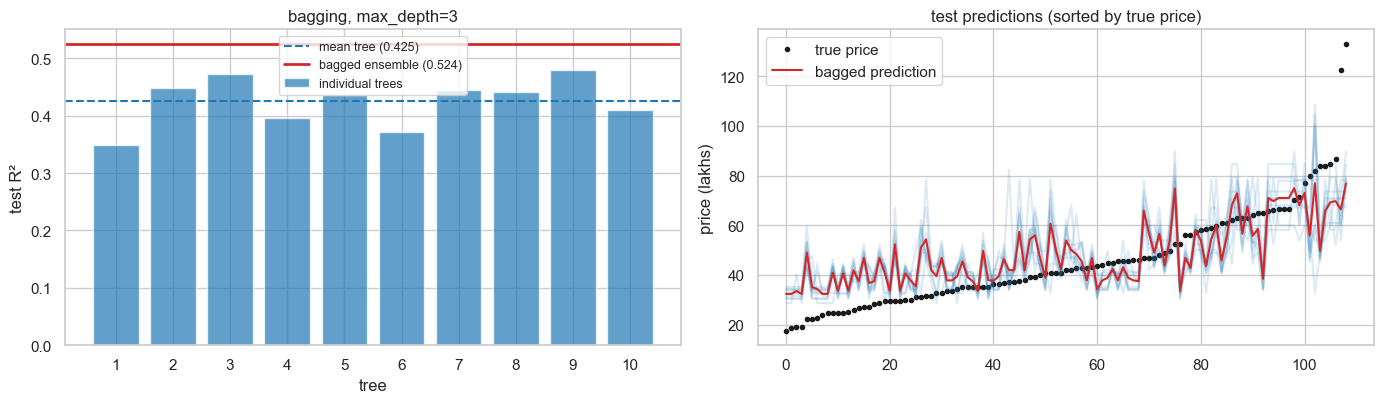

In [9]:
tree_preds = np.array([t.predict(Xtest) for t in trees])
tree_r2 = np.array([r2(ytest, p) for p in tree_preds])
bag_r2 = r2(ytest, tree_preds.mean(0))
results['q1_bagging'] = {'tree_r2': tree_r2.round(4).tolist(), 'mean_tree_r2': float(tree_r2.mean()),
                         'std_tree_r2': float(tree_r2.std()), 'bagged_r2': float(bag_r2), 'depth': best_depth}
print(pd.Series(tree_r2, index=[f'tree {i+1}' for i in range(10)]).round(4).to_string())
print(f'\naverage single tree R² = {tree_r2.mean():.4f} ± {tree_r2.std():.4f}')
print(f'bagged ensemble R²     = {bag_r2:.4f}')

fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
ax[0].bar(range(1, 11), tree_r2, color='tab:blue', alpha=0.7, label='individual trees')
ax[0].axhline(tree_r2.mean(), c='tab:blue', ls='--', label=f'mean tree ({tree_r2.mean():.3f})')
ax[0].axhline(bag_r2, c='tab:red', lw=2, label=f'bagged ensemble ({bag_r2:.3f})')
ax[0].set_xlabel('tree'); ax[0].set_ylabel('test R²'); ax[0].set_xticks(range(1, 11)); ax[0].legend(fontsize=9)
ax[0].set_title(f'bagging, max_depth={best_depth}')
order = np.argsort(ytest)
ax[1].plot(ytest[order], 'k.', label='true price')
ax[1].plot(tree_preds[:, order].T, alpha=0.15, c='tab:blue')
ax[1].plot(tree_preds.mean(0)[order], c='tab:red', lw=1.5, label='bagged prediction')
ax[1].set_title('test predictions (sorted by true price)'); ax[1].set_ylabel('price (lakhs)'); ax[1].legend()
plt.tight_layout(); savefig('q1_bagging'); plt.show()

### 8. What happens when `max_depth` changes?

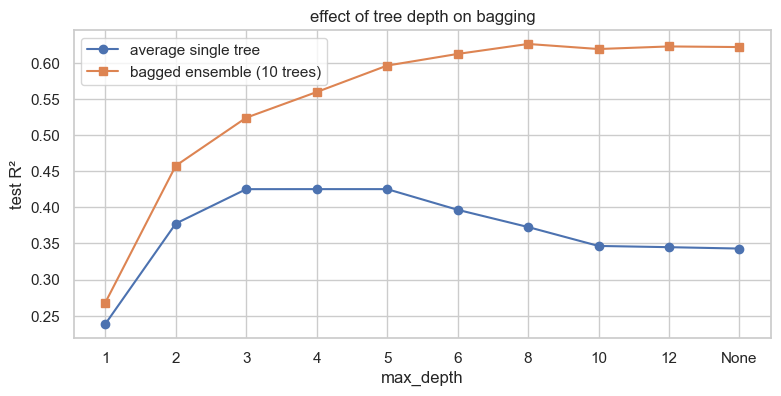

,max_depth,mean tree R²,bagged R²,gain from bagging
0,1,0.2384,0.2680,0.0296
1,2,0.3775,0.4577,0.0802
2,3,0.4252,0.5243,0.0990
3,4,0.4253,0.5598,0.1346
4,5,0.4253,0.5965,0.1712
5,6,0.3966,0.6126,0.2160
6,8,0.3727,0.6264,0.2537
7,10,0.3465,0.6194,0.2729
8,12,0.3448,0.6230,0.2782
9,None,0.3429,0.6221,0.2792


In [10]:
rows = []
for d in [1, 2, 3, 4, 5, 6, 8, 10, 12, None]:
    ts = bootstrap_trees(Xtrain, ytrain, 10, d)
    ps = np.array([t.predict(Xtest) for t in ts])
    ind = [r2(ytest, p) for p in ps]
    rows.append({'max_depth': 'None' if d is None else d, 'mean tree R²': np.mean(ind),
                 'bagged R²': r2(ytest, ps.mean(0)), 'gain from bagging': r2(ytest, ps.mean(0)) - np.mean(ind)})
depth_bag = pd.DataFrame(rows)
results['q1_depth_bagging'] = depth_bag.round(4).to_dict('records')

x = np.arange(len(depth_bag))
plt.figure(figsize=(9, 4))
plt.plot(x, depth_bag['mean tree R²'], 'o-', label='average single tree')
plt.plot(x, depth_bag['bagged R²'], 's-', label='bagged ensemble (10 trees)')
plt.xticks(x, depth_bag['max_depth']); plt.xlabel('max_depth'); plt.ylabel('test R²'); plt.legend()
plt.title('effect of tree depth on bagging'); savefig('q1_depth_bagging'); plt.show()
depth_bag.round(4)

### 9–10. Random Forest and AdaBoost (sklearn)

In [11]:
rf = RandomForestRegressor(n_estimators=200, random_state=SEED).fit(Xtrain, ytrain)
ada = AdaBoostRegressor(n_estimators=200, learning_rate=0.05, random_state=SEED).fit(Xtrain, ytrain)
bag_pred = tree_preds.mean(0)
summary = pd.DataFrame({
    name: {'MSE': mean_squared_error(ytest, p), 'MAE': mean_absolute_error(ytest, p), 'R²': r2(ytest, p)}
    for name, p in [('single tree (CV depth)', CART('regression', max_depth=best_depth).fit(Xtrain, ytrain).predict(Xtest)),
                    ('bagging (10 trees, scratch)', bag_pred),
                    ('Random Forest', rf.predict(Xtest)),
                    ('AdaBoost', ada.predict(Xtest))]}).T
results['q1_models'] = summary.round(4).to_dict('index')
summary.round(3)

,MSE,MAE,R²
single tree (CV depth),211.148,10.998,0.480
"bagging (10 trees, scratch)",193.104,10.498,0.524
Random Forest,140.212,8.370,0.655
AdaBoost,178.510,10.201,0.560


# Question 2 — Breast cancer (classification)

(569, 6) | missing: 0 | class balance: {1: 357, 0: 212}


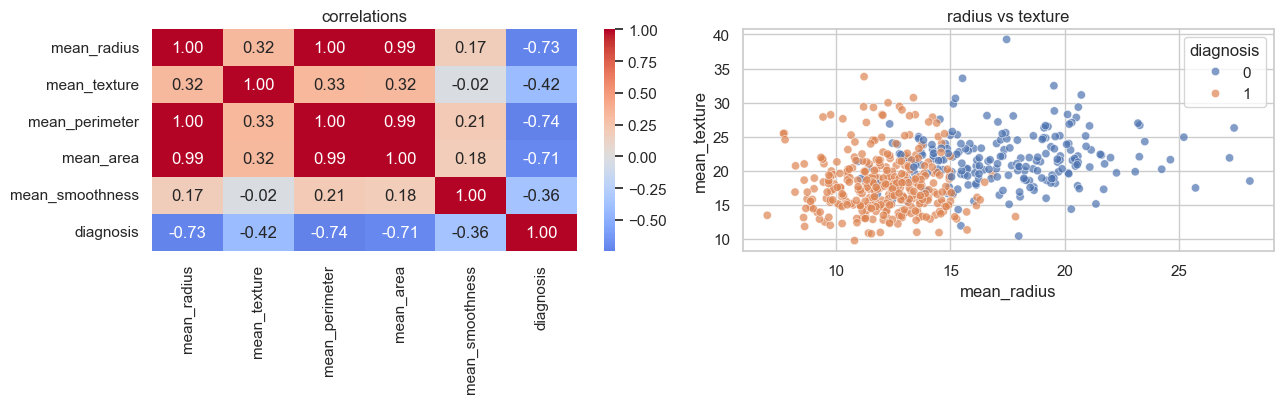

In [12]:
bc = pd.read_csv('data/Breast_cancer_data.csv')
print(bc.shape, '| missing:', bc.isna().sum().sum(), '| class balance:', bc['diagnosis'].value_counts().to_dict())
B_FEATS = bc.columns.drop('diagnosis').tolist()
Xb, yb = bc[B_FEATS].values, bc['diagnosis'].values
Xb_tr, Xb_te, yb_tr, yb_te = train_test_split(Xb, yb, test_size=0.2, stratify=yb, random_state=SEED)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
sns.heatmap(bc.corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=ax[0]); ax[0].set_title('correlations')
sns.scatterplot(data=bc, x='mean_radius', y='mean_texture', hue='diagnosis', alpha=0.7, ax=ax[1]); ax[1].set_title('radius vs texture')
plt.tight_layout(); savefig('q2_eda'); plt.show()

`diagnosis` is already 0/1 and the 5 features are numeric with no missing values. Radius, perimeter and area are almost perfectly correlated (they are all measures of size). That does not hurt trees, but it does mean a tree mostly uses one of them. Split 80:20, stratified.

### 1. Single fully-grown decision tree (scratch, Gini)

In [13]:
clf_full = CART('classification').fit(Xb_tr, yb_tr)
acc_tr_full, acc_te_full = accuracy(yb_tr, clf_full.predict(Xb_tr)), accuracy(yb_te, clf_full.predict(Xb_te))
results['q2_t1'] = {'train_acc': acc_tr_full, 'test_acc': acc_te_full}
print(f'accuracy train = {acc_tr_full:.4f} | test = {acc_te_full:.4f}')

accuracy train = 1.0000 | test = 0.9123


### 2–3. 5-fold CV for `max_depth`

best max_depth = 5 | CV acc = 0.8989 | test acc = 0.9474


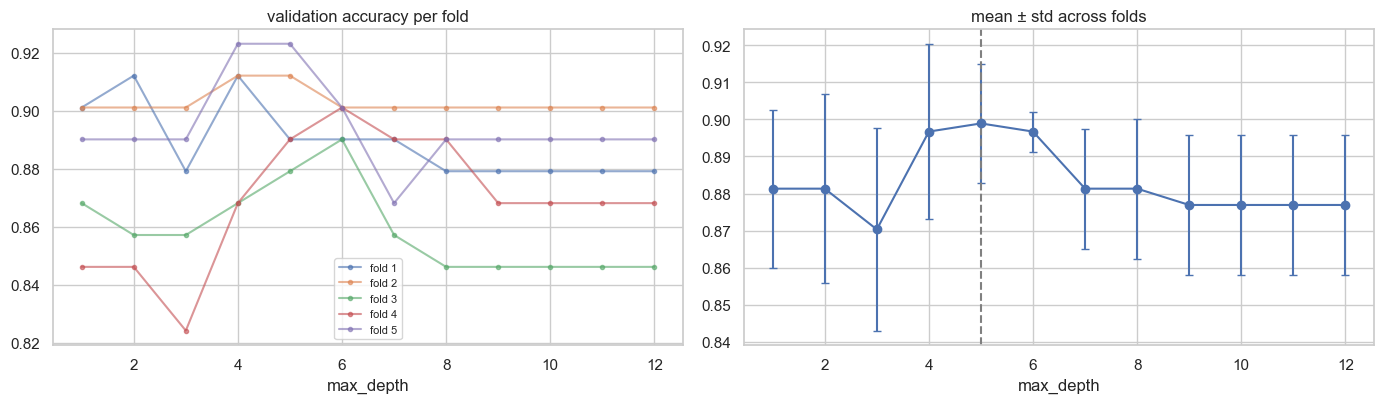

In [14]:
skf = StratifiedKFold(5, shuffle=True, random_state=SEED)
cdepths = range(1, 13)
cvc = np.zeros((len(cdepths), 5))
for i, d in enumerate(cdepths):
    for k, (tr, va) in enumerate(skf.split(Xb_tr, yb_tr)):
        m = CART('classification', max_depth=d).fit(Xb_tr[tr], yb_tr[tr])
        cvc[i, k] = accuracy(yb_tr[va], m.predict(Xb_tr[va]))
best_cdepth = int(list(cdepths)[cvc.mean(1).argmax()])
best_clf = CART('classification', max_depth=best_cdepth).fit(Xb_tr, yb_tr)
results['q2_cv'] = {'best_depth': best_cdepth, 'mean_acc': dict(zip(cdepths, cvc.mean(1).round(4))),
                    'std_acc': dict(zip(cdepths, cvc.std(1).round(4))),
                    'test_acc_best_depth': accuracy(yb_te, best_clf.predict(Xb_te))}
print('best max_depth =', best_cdepth, '| CV acc =', round(cvc.mean(1).max(), 4),
      '| test acc =', round(results['q2_cv']['test_acc_best_depth'], 4))

fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
for k in range(5):
    ax[0].plot(list(cdepths), cvc[:, k], 'o-', ms=3, alpha=0.6, label=f'fold {k+1}')
ax[0].set_title('validation accuracy per fold'); ax[0].set_xlabel('max_depth'); ax[0].legend(fontsize=8)
ax[1].errorbar(list(cdepths), cvc.mean(1), yerr=cvc.std(1), fmt='o-', capsize=3)
ax[1].axvline(best_cdepth, ls='--', c='grey'); ax[1].set_title('mean ± std across folds'); ax[1].set_xlabel('max_depth')
plt.tight_layout(); savefig('q2_cv_depth'); plt.show()

### 4–5. XGBoost (`subsample=0.7`, `max_depth=4`)

In [15]:
xgbc = xgb.XGBClassifier(subsample=0.7, max_depth=4, n_estimators=200, learning_rate=0.1,
                         random_state=SEED, eval_metric='logloss').fit(Xb_tr, yb_tr)
xgb_tr, xgb_te = accuracy(yb_tr, xgbc.predict(Xb_tr)), accuracy(yb_te, xgbc.predict(Xb_te))
results['q2_xgb'] = {'train_acc': xgb_tr, 'test_acc': xgb_te}
print(f'XGBoost accuracy  train = {xgb_tr:.4f} | test = {xgb_te:.4f}')

XGBoost accuracy  train = 1.0000 | test = 0.9561


### 6–7. LightGBM: `max_depth=3` with different `num_leaves`, and the depth/leaves relation
A depth-*d* binary tree can hold at most 2^d leaves, so with `max_depth=3`, any `num_leaves` > 8 has no effect. LightGBM grows trees **leaf-wise** (always splitting the leaf with the largest loss reduction). Because of that, `num_leaves` is its main complexity control, and `max_depth` is a cap on top of it.

In [16]:
def lgbm(depth, leaves, n=200):
    m = lgb.LGBMClassifier(max_depth=depth, num_leaves=leaves, n_estimators=n, learning_rate=0.1,
                           min_child_samples=5, random_state=SEED, verbose=-1).fit(Xb_tr, yb_tr)
    return accuracy(yb_tr, m.predict(Xb_tr)), accuracy(yb_te, m.predict(Xb_te))

leaf_rows = [{'num_leaves': L, **dict(zip(['train acc', 'test acc'], lgbm(3, L)))} for L in [2, 3, 4, 5, 6, 7, 8, 12, 16, 32]]
leaf_df = pd.DataFrame(leaf_rows)
results['q2_lgbm_depth3'] = leaf_df.round(4).to_dict('records')
leaf_df.round(4)

,num_leaves,train acc,test acc
0,2,0.9582,0.9474
1,3,0.9890,0.9561
2,4,1.0000,0.9474
3,5,1.0000,0.9474
4,6,1.0000,0.9561
5,7,1.0000,0.9386
6,8,1.0000,0.9561
7,12,1.0000,0.9561
8,16,1.0000,0.9561
9,32,1.0000,0.9561


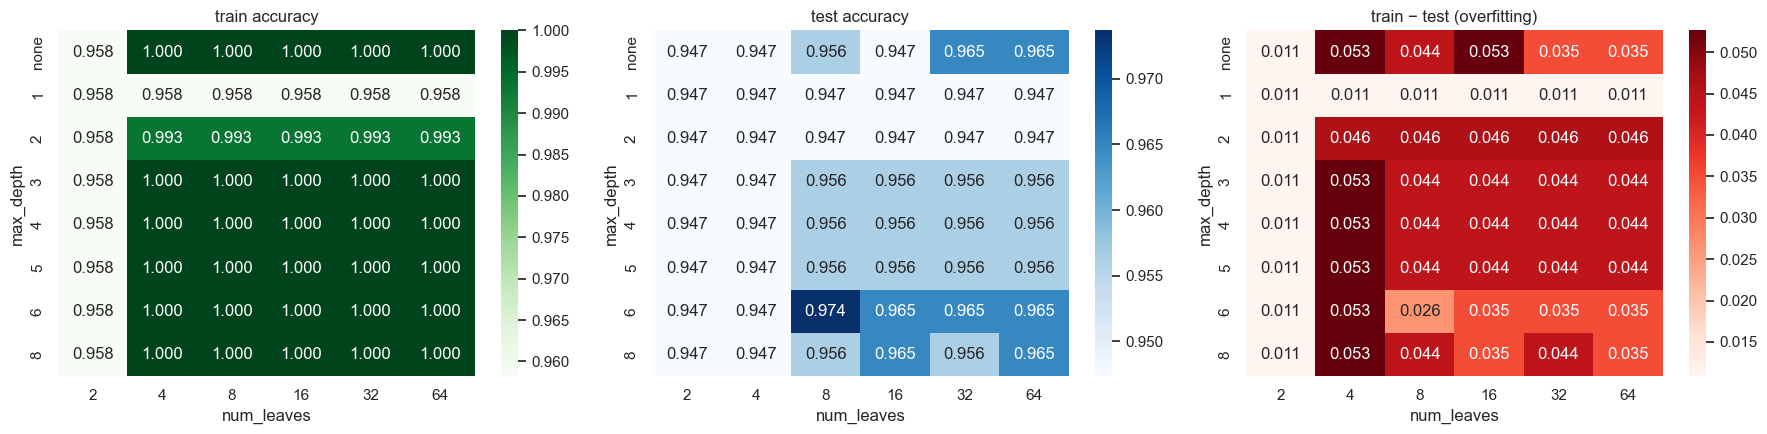

In [17]:
grid = []
for d in [1, 2, 3, 4, 5, 6, 8, -1]:
    for L in [2, 4, 8, 16, 32, 64]:
        tr, te = lgbm(d, L)
        grid.append({'max_depth': d, 'num_leaves': L, 'train': tr, 'test': te, 'gap': tr - te})
grid = pd.DataFrame(grid)
results['q2_lgbm_grid'] = grid.round(4).to_dict('records')

fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
for a, col, cmap in zip(ax, ['train', 'test', 'gap'], ['Greens', 'Blues', 'Reds']):
    sns.heatmap(grid.pivot(index='max_depth', columns='num_leaves', values=col).rename(index={-1: 'none'}),
                annot=True, fmt='.3f', cmap=cmap, ax=a)
    a.set_title({'train': 'train accuracy', 'test': 'test accuracy', 'gap': 'train − test (overfitting)'}[col])
plt.tight_layout(); savefig('q2_lgbm_grid'); plt.show()

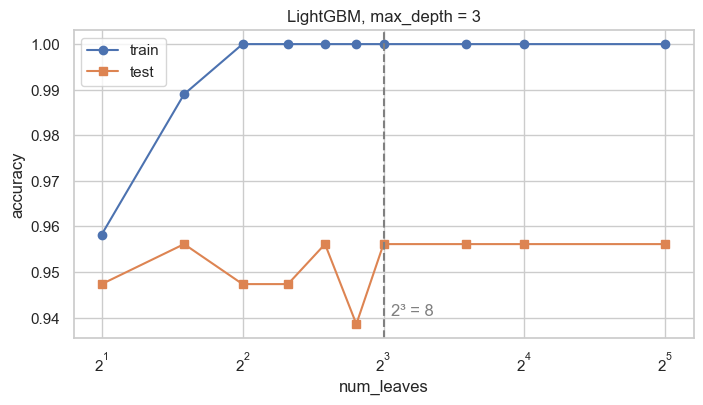

In [18]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(leaf_df['num_leaves'], leaf_df['train acc'], 'o-', label='train')
ax.plot(leaf_df['num_leaves'], leaf_df['test acc'], 's-', label='test')
ax.axvline(8, ls='--', c='grey'); ax.text(8.3, ax.get_ylim()[0] + 0.005, '2³ = 8', color='grey')
ax.set_xscale('log', base=2); ax.set_xlabel('num_leaves'); ax.set_ylabel('accuracy'); ax.legend()
ax.set_title('LightGBM, max_depth = 3'); savefig('q2_lgbm_leaves'); plt.show()

Accuracy on 114 test samples moves in steps of 0.9%, so it is a blunt instrument for spotting overfitting. **Log-loss** uses the predicted probabilities, so it shows the moment the model becomes over-confident on training data and starts to hurt on unseen data.

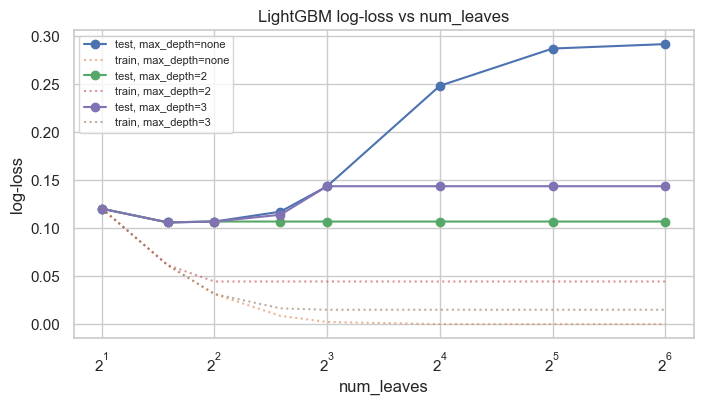

max_depth,-1,2,3
num_leaves,,,
2,0.1202,0.1202,0.1202
3,0.1059,0.1059,0.1059
4,0.1068,0.1068,0.1068
6,0.1171,0.1068,0.1139
8,0.1435,0.1068,0.1436
16,0.2482,0.1068,0.1436
32,0.2870,0.1068,0.1436
64,0.2916,0.1068,0.1436


In [19]:
from sklearn.metrics import log_loss
ll_rows = []
for d in [2, 3, -1]:
    for L in [2, 3, 4, 6, 8, 16, 32, 64]:
        m = lgb.LGBMClassifier(max_depth=d, num_leaves=L, n_estimators=200, learning_rate=0.1,
                               min_child_samples=5, random_state=SEED, verbose=-1).fit(Xb_tr, yb_tr)
        ll_rows.append({'max_depth': d, 'num_leaves': L,
                        'train logloss': log_loss(yb_tr, m.predict_proba(Xb_tr)),
                        'test logloss': log_loss(yb_te, m.predict_proba(Xb_te))})
ll = pd.DataFrame(ll_rows)
results['q2_lgbm_logloss'] = ll.round(4).to_dict('records')
fig, ax = plt.subplots(figsize=(8, 4))
for d, g in ll.groupby('max_depth'):
    lbl = 'none' if d == -1 else d
    ax.plot(g['num_leaves'], g['test logloss'], 'o-', label=f'test, max_depth={lbl}')
    ax.plot(g['num_leaves'], g['train logloss'], ':', alpha=0.6, label=f'train, max_depth={lbl}')
ax.set_xscale('log', base=2); ax.set_xlabel('num_leaves'); ax.set_ylabel('log-loss'); ax.legend(fontsize=8)
ax.set_title('LightGBM log-loss vs num_leaves'); savefig('q2_lgbm_logloss'); plt.show()
ll.pivot(index='num_leaves', columns='max_depth', values='test logloss').round(4)



In [20]:
with open('results.json', 'w') as f:
    json.dump(results, f, indent=2, default=float)